# 1. Imports

In [42]:
import MDSplus as mds
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import stft
import pandas as pd

# 2. Parameters

In [94]:
shot = 24126
number_of_coils = list(range(22)) #Mirnov coils from BBMRNV000 to BBMRNV021 
nlin, ncol = 5, 5  

# STFT
nperseg, noverlap = 2048, 1536

# anlysis
window_ms = (32, 140)          # time window for plasma
width_khz = (10, 20)           # best frame to search the mode
delta_khz = 1.0                # how much the peak can move in frequency to be considered the same mode
r_int_khz, r_ext_khz = 1.5, 5.0  # noise around the peak to calculate SNR
low_db = 10                    # minimum SNR to accept a frame
hole_max = 2                   # 2 frame max holes that can be accepted to consider a mode as continuous

# spectogram color code
vmin, vmax = -120, -20

# 3. Load channels

In [95]:
def channel_load(shot: int, no: str, servidor: str = "tcabrcl.if.usp.br:8000"):
    """Reads a channel from the TCABR MDSplus tree and returns (time, signal)."""
    conn = mds.Connection(servidor)
    conn.openTree("tcabr_shot", shot)
    try:
        sinal = conn.get(no).data()
        tempo = conn.get(f"dim_of({no})").data()
    finally:
        conn.closeTree("tcabr_shot", shot)
    return tempo, sinal


def mirnov_select(shot, mirnov):
    no = rf"\TCABR_SHOT::TOP.ACQSIGNALS.BBMRNV{mirnov:03d}:SIGNAL"
    return channel_load(shot, no)


def carregar_todas(shot, numeros):
    """Returns {bobina: (tempo, sinal)}. Channels that fail go to `falhas`."""
    dados, falhas = {}, {}
    for n in numeros:
        try:
            dados[n] = mirnov_select(shot, n)
        except Exception as e:
            falhas[n] = type(e).__name__
    return dados, falhas

dados, falhas = carregar_todas(shot, number_of_coils) 

# 4. STFT of each coil

In [96]:
def calcular_espectro(tempo, sinal):
    t_s = np.asarray(tempo) / 1000
    fs = 1 / np.median(np.diff(t_s))
    sinal = sinal - np.mean(sinal)
    f, t_rel, Z = stft(sinal, fs=fs, window="hann", nperseg=nperseg, noverlap=noverlap)
    return dict(f_khz=f / 1000, t_ms=(t_s[0] + t_rel) * 1000, power=np.abs(Z) ** 2)


espectros = {n: calcular_espectro(*dados[n]) for n in dados}

# 5. Function to plot a 5x5 image of graphs

In [97]:
def grade(desenhar, fonte, ylabel, sharey=False, figsize=(18, 12), cbar=None):
    fig, axs = plt.subplots(nlin, ncol, figsize=figsize, sharex=True, sharey=sharey, constrained_layout=True)
    mesh = None
    for pos, ax in enumerate(axs.ravel()):
        if pos >= len(number_of_coils):   
            ax.axis("off")
            continue
        n = number_of_coils[pos]
        ax.set_title(f"Mirnov Coil {n+1}", fontsize=10, fontweight="bold")
        if n not in fonte:
            ax.text(0.5, 0.5, "sem dados", ha="center", va="center", transform=ax.transAxes, color="gray")
            continue
        saida = desenhar(ax, n)
        if saida is not None:          
            mesh = saida
    if cbar and mesh is not None:
        fig.colorbar(mesh, ax=axs, label=cbar, shrink=0.6)
    fig.supxlabel("Time (ms)", fontsize=14, fontweight="bold")
    fig.supylabel(ylabel, fontsize=14, fontweight="bold")
    return fig, axs

# 6. Raw signal and spectogram

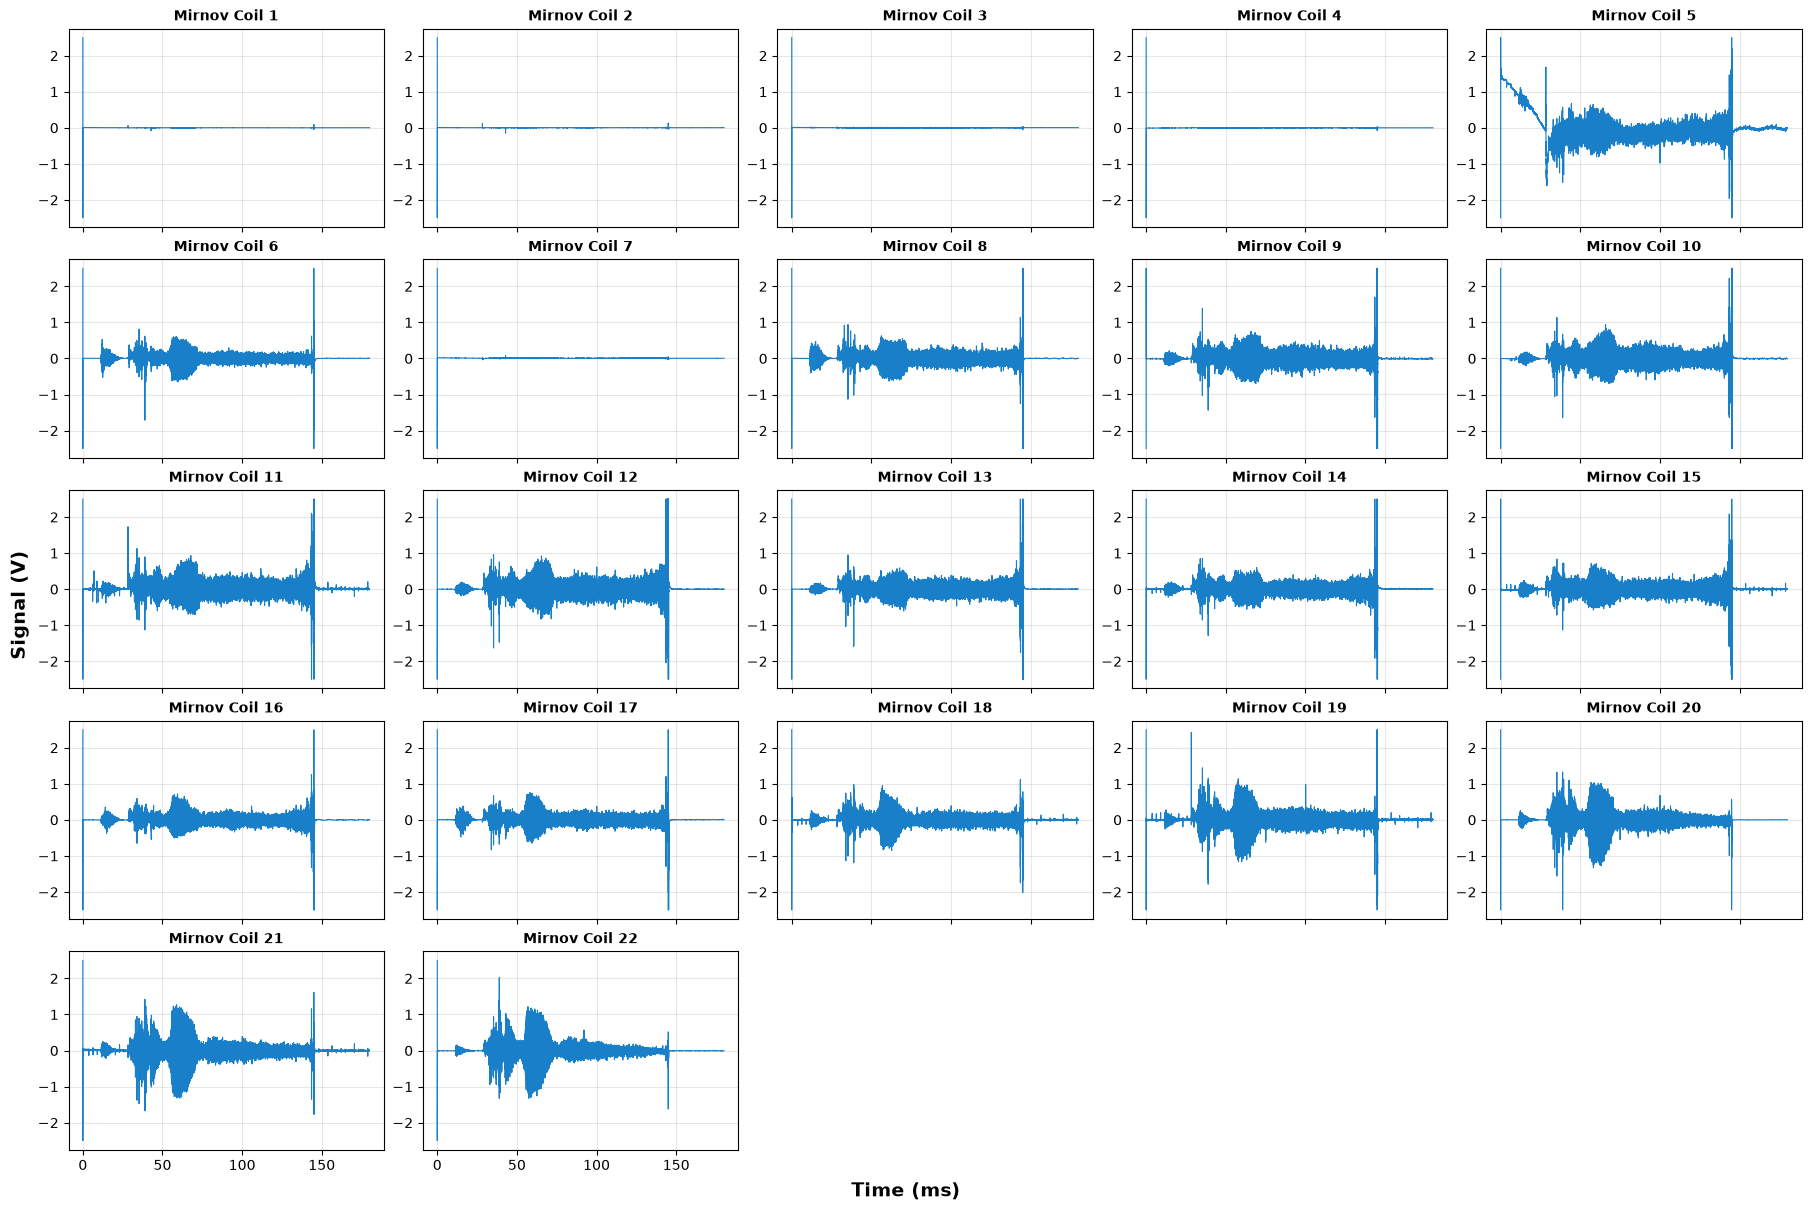

In [98]:
def desenha_sinal(ax, n):
    t, s = dados[n]
    ax.plot(t, s, color="#187fc8", linewidth=0.8)
    ax.grid(True, alpha=0.3)


grade(desenha_sinal, dados, "Signal (V)")
plt.show()

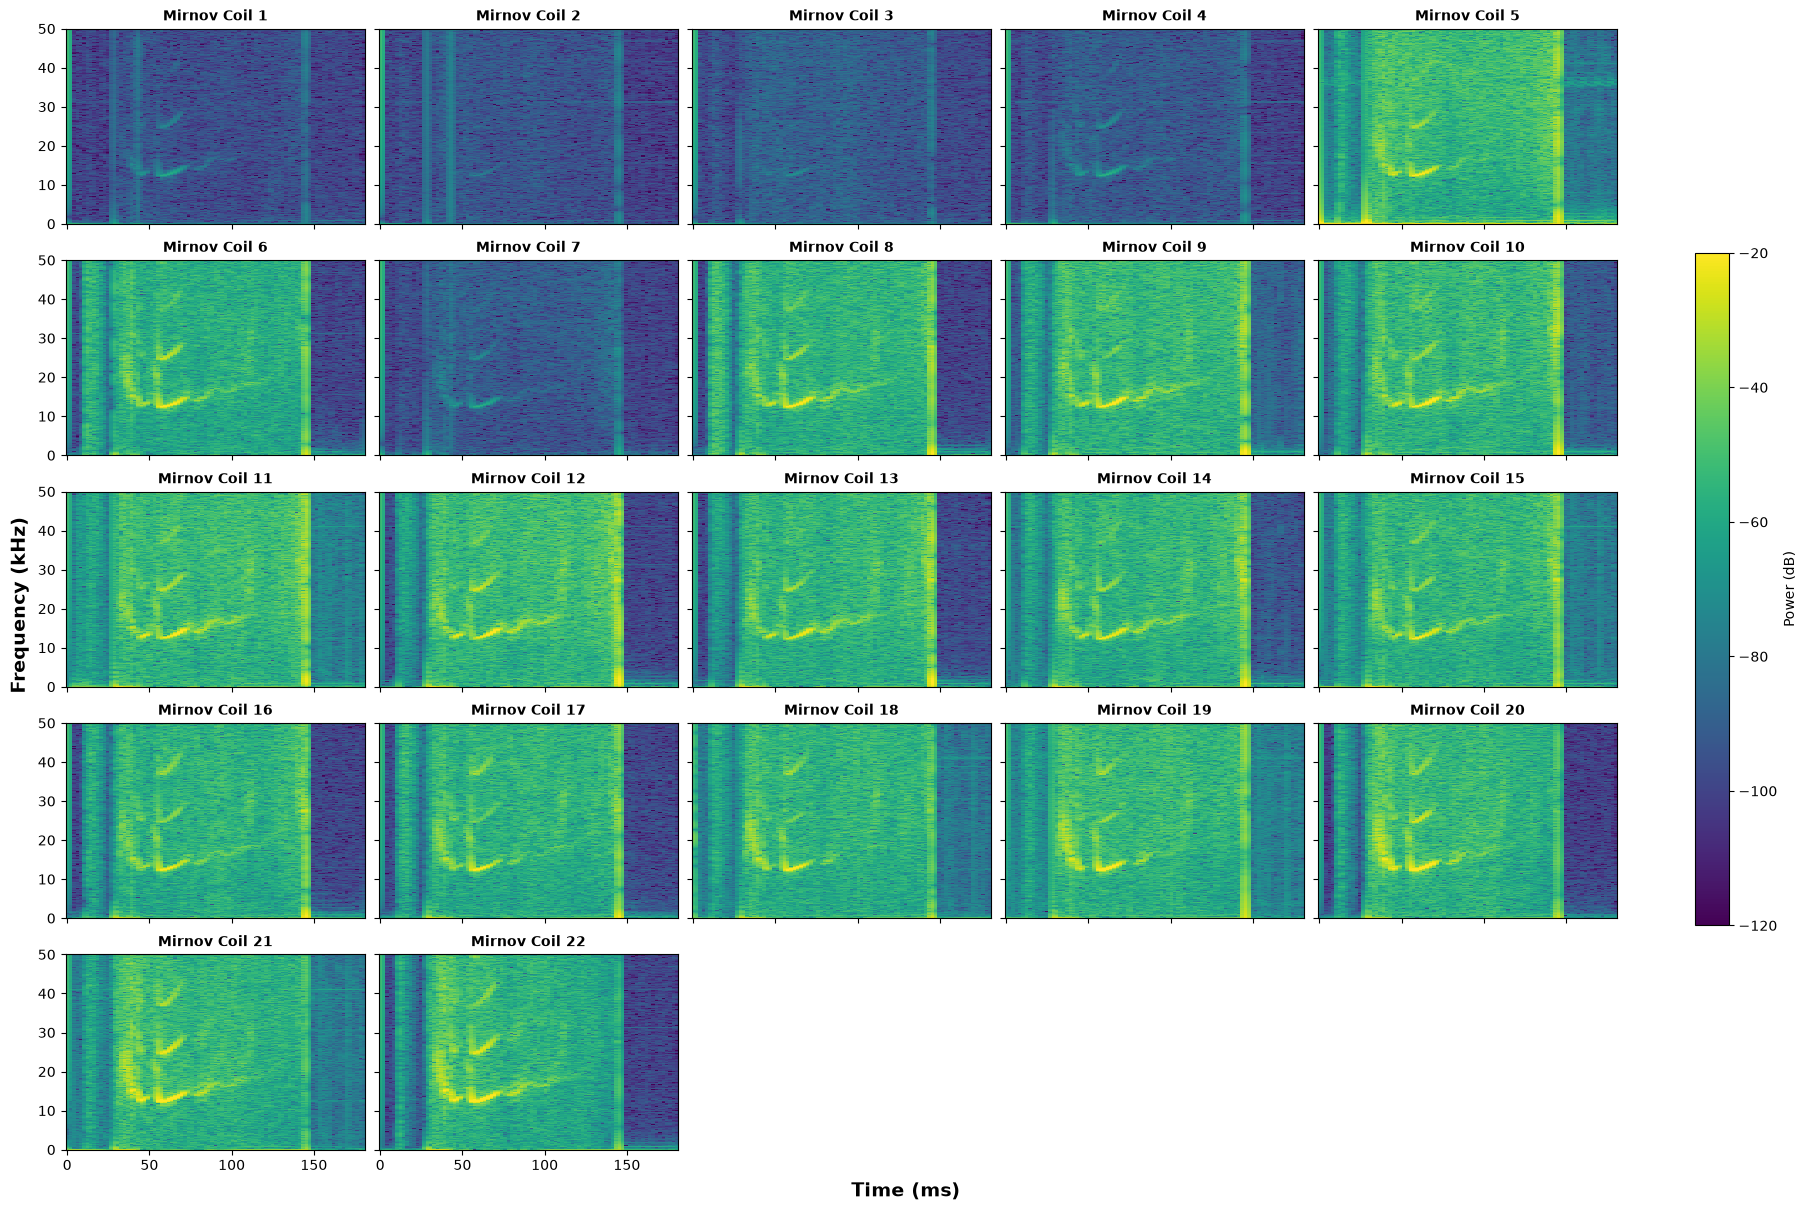

In [99]:
def desenha_espectro(ax, n):
    e = espectros[n]
    ax.set_ylim(0, 50)
    return ax.pcolormesh(e["t_ms"], e["f_khz"], 10 * np.log10(e["power"] + 1e-20), shading="auto", cmap="viridis", vmin=vmin, vmax=vmax, rasterized=True)


grade(desenha_espectro, espectros, "Frequency (kHz)", sharey=True, cbar="Power (dB)")
plt.show()

# 7. Coil analysis

In [100]:
def ruido_medio(P, f_khz, f_centro):
    """Média linear da potência na coroa [r_int_khz, r_ext_khz] kHz em volta de f_centro (um valor por frame)."""
    dist = np.abs(f_khz[:, None] - f_centro[None, :])
    coroa = (dist >= r_int_khz) & (dist <= r_ext_khz)
    with np.errstate(all="ignore"):
        return np.nanmean(np.where(coroa, P, np.nan), axis=0)


def rastrear(P_db, f_khz, k0, f0):
    """Segue o pico por continuidade, a partir da semente k0, para frente e para trás."""
    n = P_db.shape[1]
    f_track = np.full(n, np.nan)
    pico = np.full(n, np.nan)

    def percorrer(ks):
        f_prev = f0
        for k in ks:
            m = np.abs(f_khz - f_prev) <= delta_khz
            if not m.any():
                break
            col = P_db[m, k]
            j = np.argmax(col)
            f_prev = f_khz[m][j]
            f_track[k], pico[k] = f_prev, col[j]

    percorrer(range(k0, n))             
    percorrer(range(k0 - 1, -1, -1))   
    return f_track, pico


def analisar(esp):
    f_khz, t_ms, power = esp["f_khz"], esp["t_ms"], esp["power"]


    sel = (t_ms >= window_ms[0]) & (t_ms <= window_ms[1])
    P_sel, t_sel = power[:, sel], t_ms[sel]
    P_db = 10 * np.log10(P_sel + 1e-20)


    banda = (f_khz >= width_khz[0]) & (f_khz <= width_khz[1])
    f_pk = f_khz[banda][np.argmax(P_db[banda], axis=0)]
    snr0 = P_db[banda].max(axis=0) - 10 * np.log10(ruido_medio(P_sel, f_khz, f_pk) + 1e-20)
    k0 = int(np.argmax(np.where(np.isfinite(snr0), snr0, -np.inf)))


    f_track, pico = rastrear(P_db, f_khz, k0, f_pk[k0])
    media = ruido_medio(P_sel, f_khz, f_track)
    SNR = pico - 10 * np.log10(media + 1e-20)
    mask = np.isfinite(SNR) & (SNR > low_db)

    out = dict(t_sel=t_sel, SNR=SNR, media=media, mask=mask, k0=k0, f_track_copy=np.where(mask, f_track, np.nan), resumo={"n_trechos": 0})
    if not mask.any():
        return out

    idx = np.where(mask)[0]
    trechos = np.split(idx, np.where(np.diff(idx) > 1)[0] + 1)                
    grupos = np.split(idx, np.where(np.diff(idx) > hole_max + 1)[0] + 1)    
    g = max(grupos, key=lambda g: t_sel[g[-1]] - t_sel[g[0]])             

    i0, i1 = max(g[0] - 1, 0), min(g[-1] + 1, len(t_sel) - 1)                 
    dur_min = t_sel[g[-1]] - t_sel[g[0]]
    inc = (t_sel[i1] - t_sel[i0] - dur_min) / 2

    # índices no vetor COMPLETO (não dentro de SNR[mask])
    i_snr = int(np.argmax(np.where(mask, SNR, -np.inf)))
    i_rui = int(np.argmax(np.where(mask, media, -np.inf)))
    rui_db = 10 * np.log10(media[mask] + 1e-20)

    out["resumo"] = dict(
        t_ini=t_sel[g[0]], t_fim=t_sel[g[-1]], duracao=dur_min + inc, incerteza=inc,
        n_trechos=len(trechos), n_atividades=len(grupos),
        f_min=f_track[mask].min(), f_max=f_track[mask].max(), f_media=f_track[mask].mean(),
        snr_medio=SNR[mask].mean(), snr_max=SNR[i_snr], t_snr_max=t_sel[i_snr],
        ruido_mediano=10 * np.log10(np.median(media[mask])),
        ruido_max=10 * np.log10(media[i_rui]), t_ruido_max=t_sel[i_rui],
        ruido_desvio=rui_db.std())
    return out

In [101]:
resultados = {}
for n, esp in espectros.items():
    try:
        resultados[n] = analisar(esp)
    except Exception as e:
        print(f"bobina {n}: {type(e).__name__}: {e}")

# 8. Trail, SNR, f(t) and noise

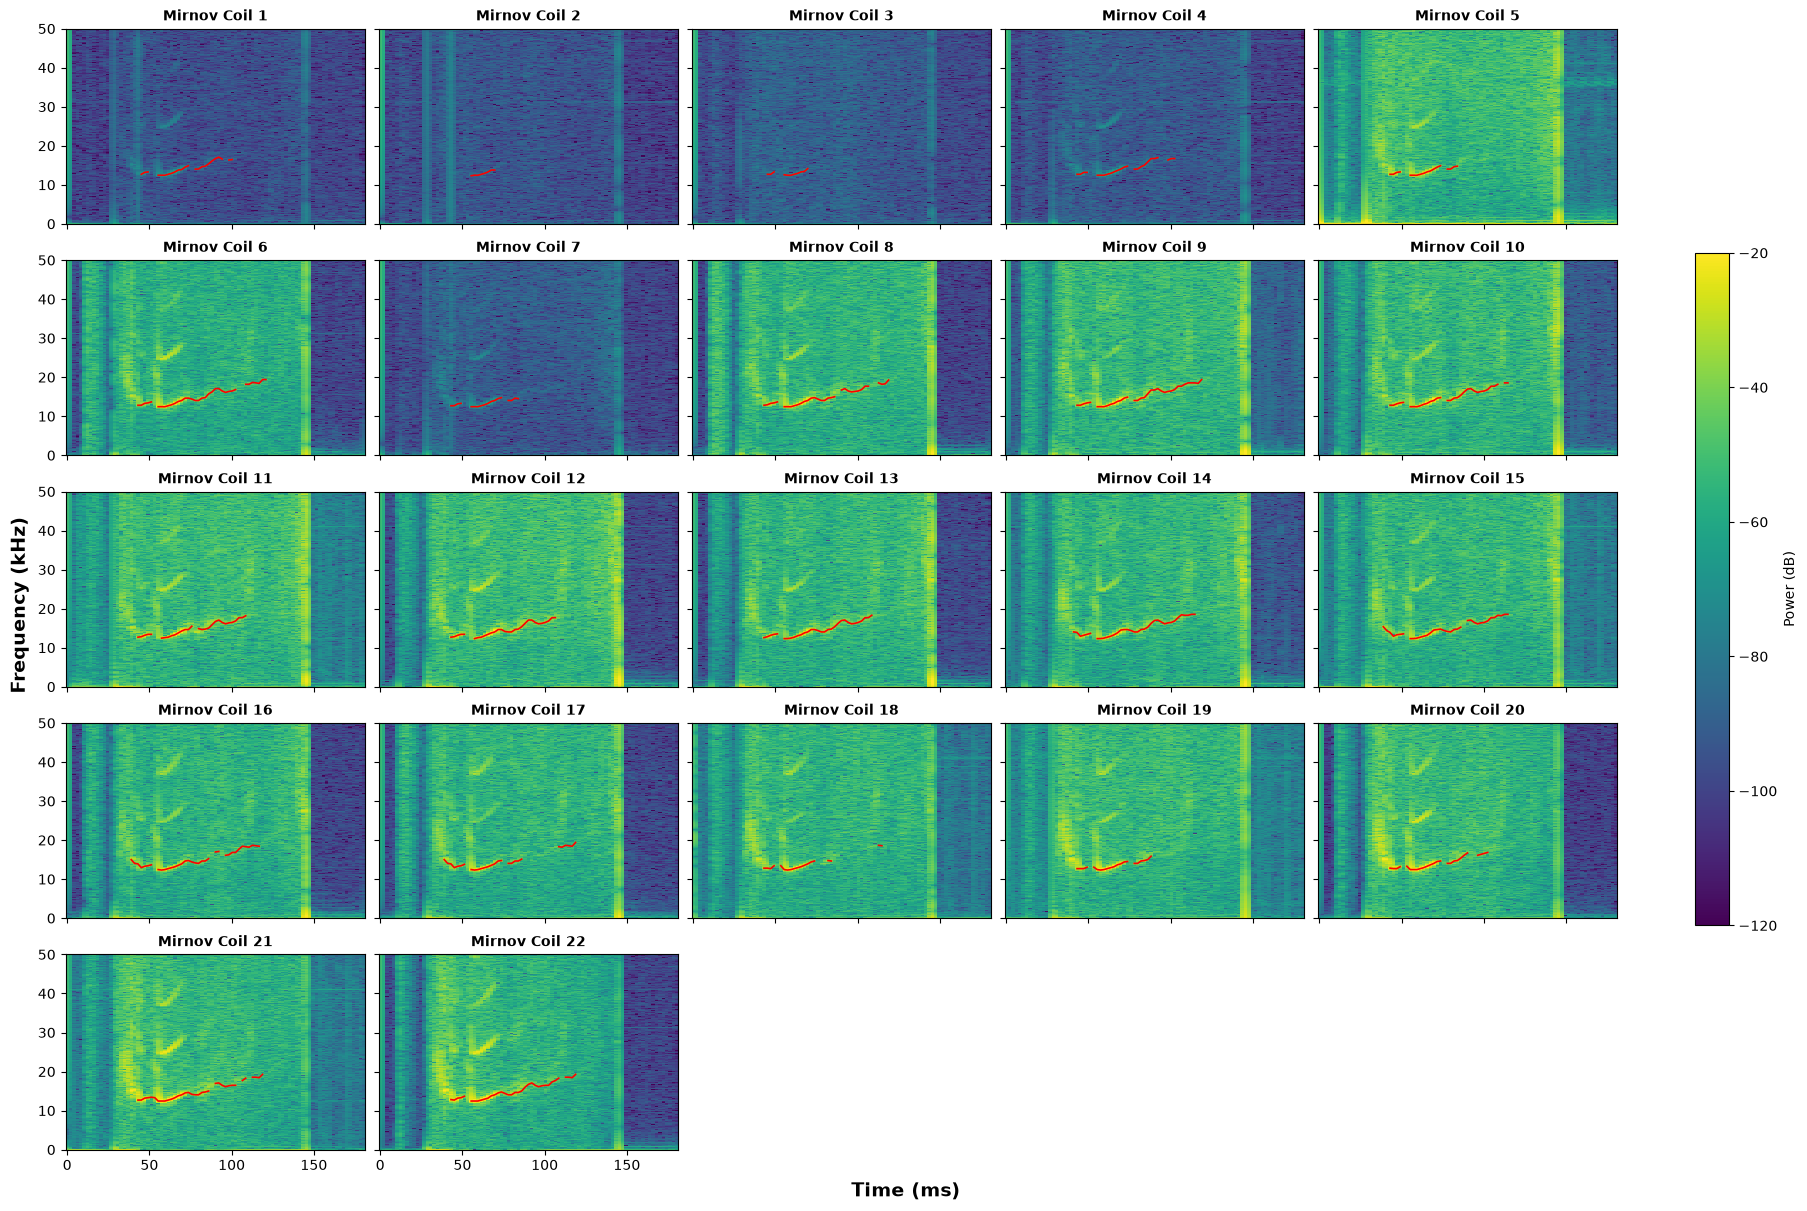

In [102]:
def desenha_trilha(ax, n):
    mesh = desenha_espectro(ax, n)
    r = resultados[n]
    ax.plot(r["t_sel"], r["f_track_copy"], "r", lw=1.2)
    return mesh


grade(desenha_trilha, resultados, "Frequency (kHz)", sharey=True, cbar="Power (dB)")
plt.show()

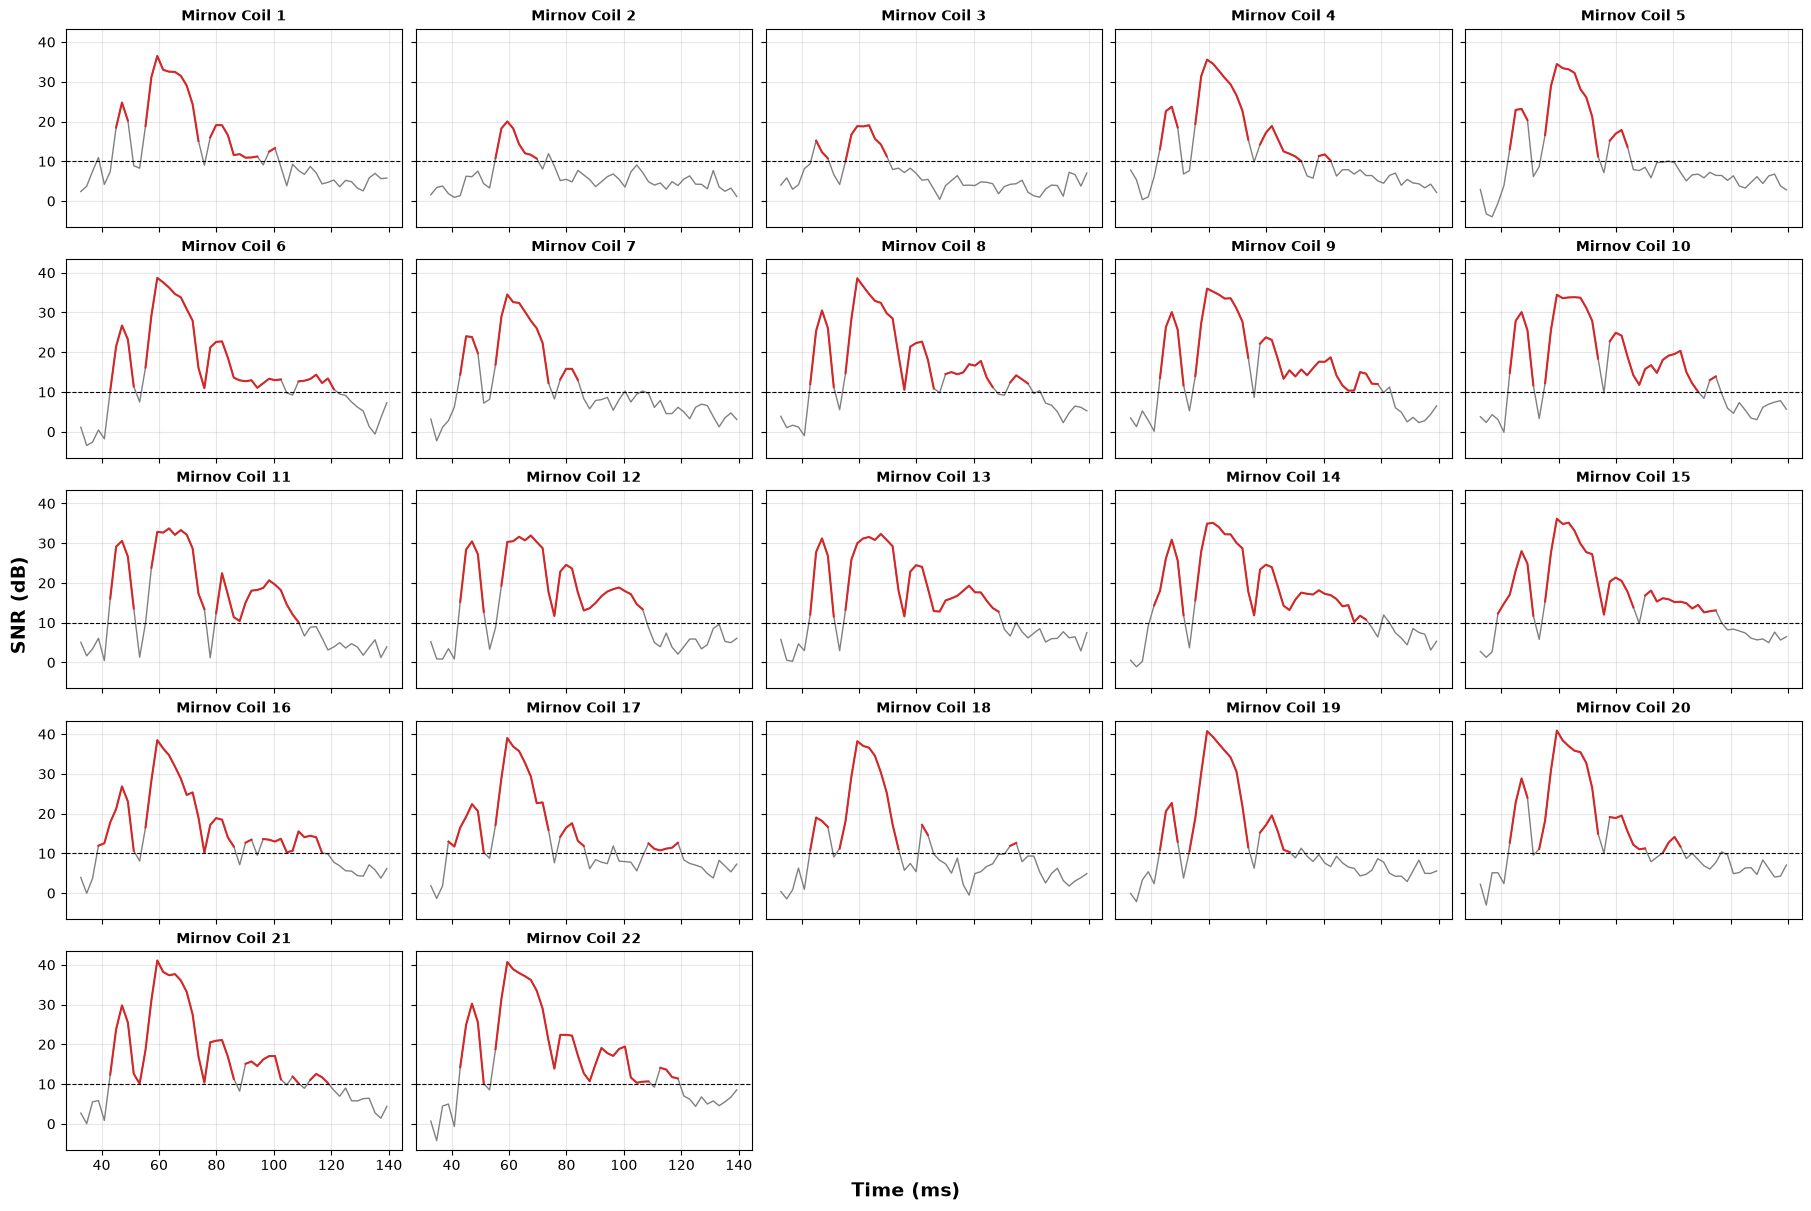

In [103]:
def desenha_snr(ax, n):
    r = resultados[n]
    ax.plot(r["t_sel"], r["SNR"], color="gray", lw=1)
    ax.plot(r["t_sel"], np.where(r["mask"], r["SNR"], np.nan), color="tab:red", lw=1.5)
    ax.axhline(low_db, color="k", ls="--", lw=0.8)
    ax.grid(True, alpha=0.3)


grade(desenha_snr, resultados, "SNR (dB)", sharey=True)
plt.show()

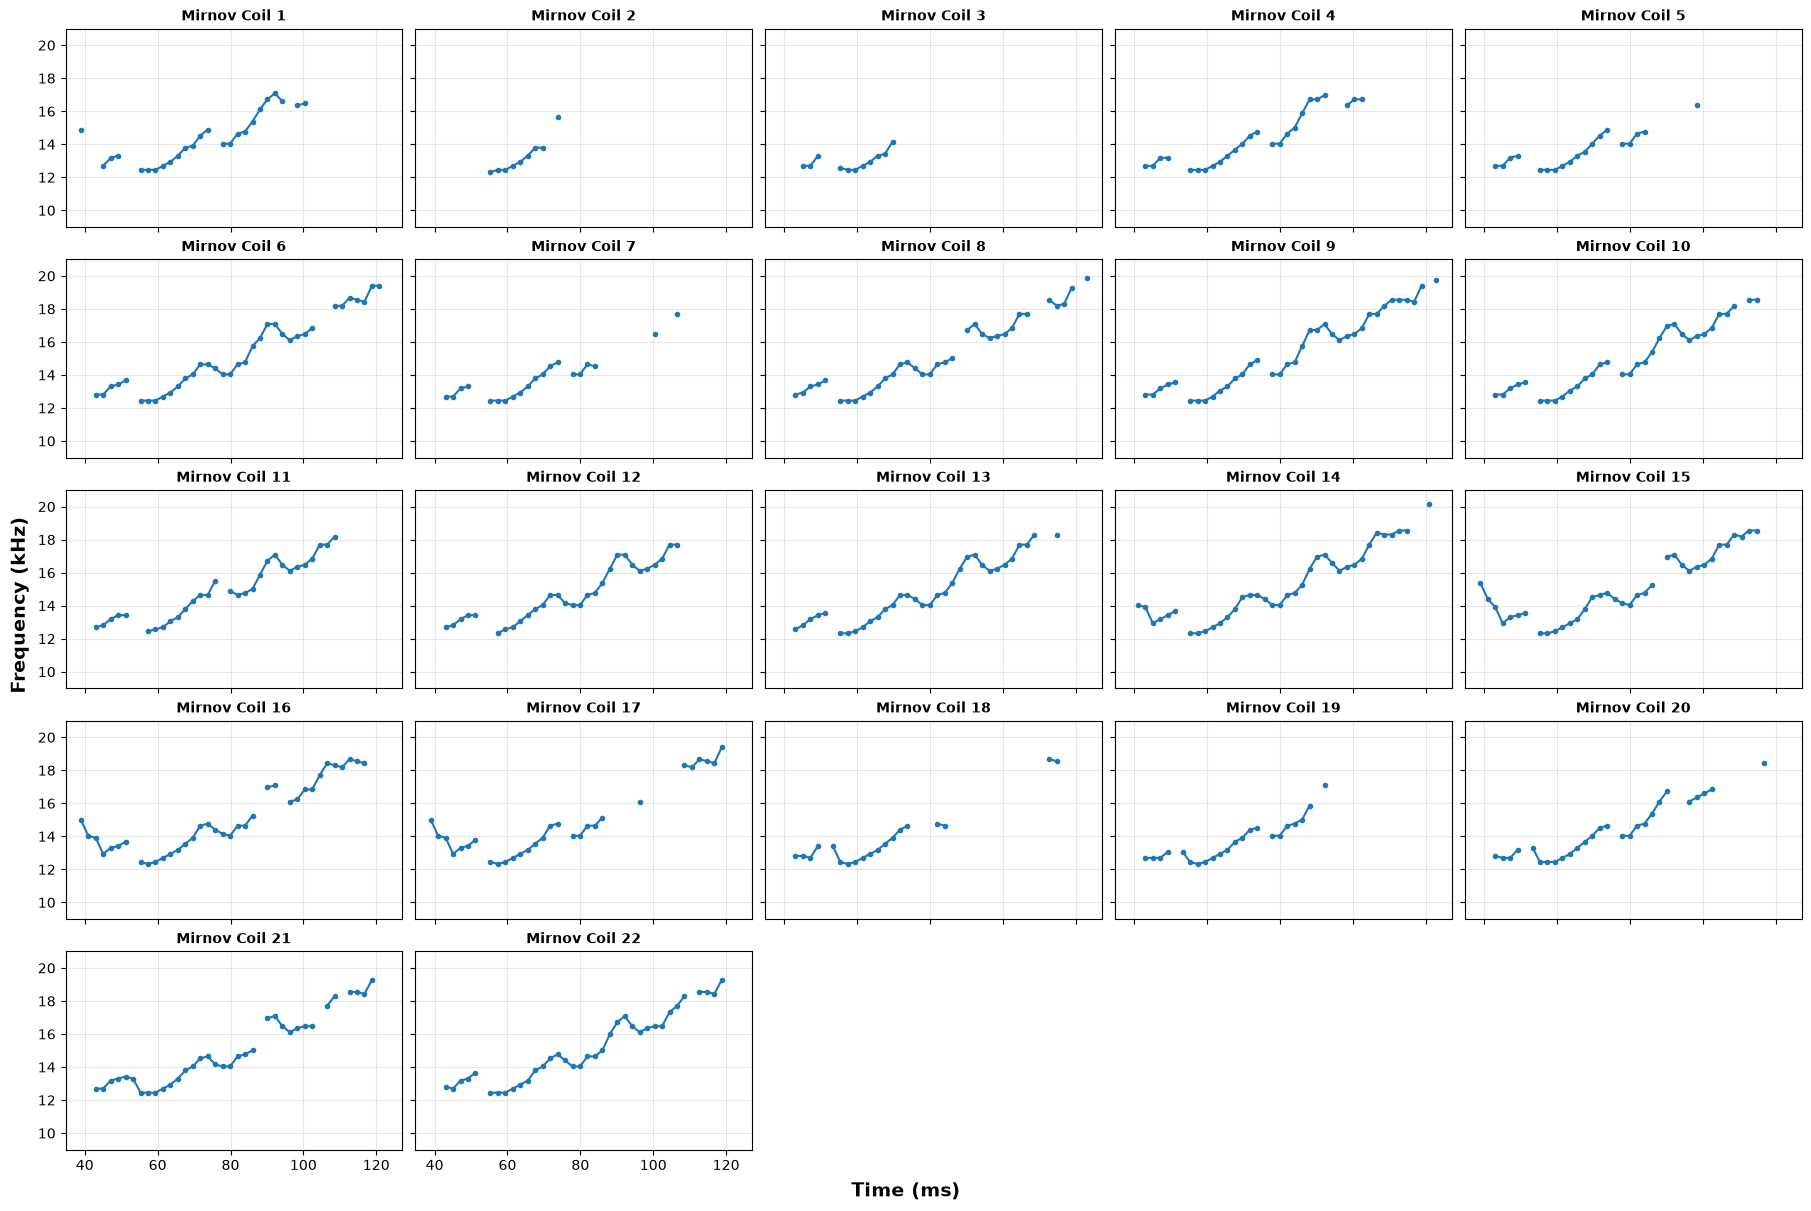

In [104]:
def desenha_ft(ax, n):
    r = resultados[n]
    ax.plot(r["t_sel"], r["f_track_copy"], "o-", ms=3)
    ax.set_ylim(width_khz[0] - 1, width_khz[1] + 1)
    ax.grid(True, alpha=0.3)


grade(desenha_ft, resultados, "Frequency (kHz)", sharey=True)
plt.show()

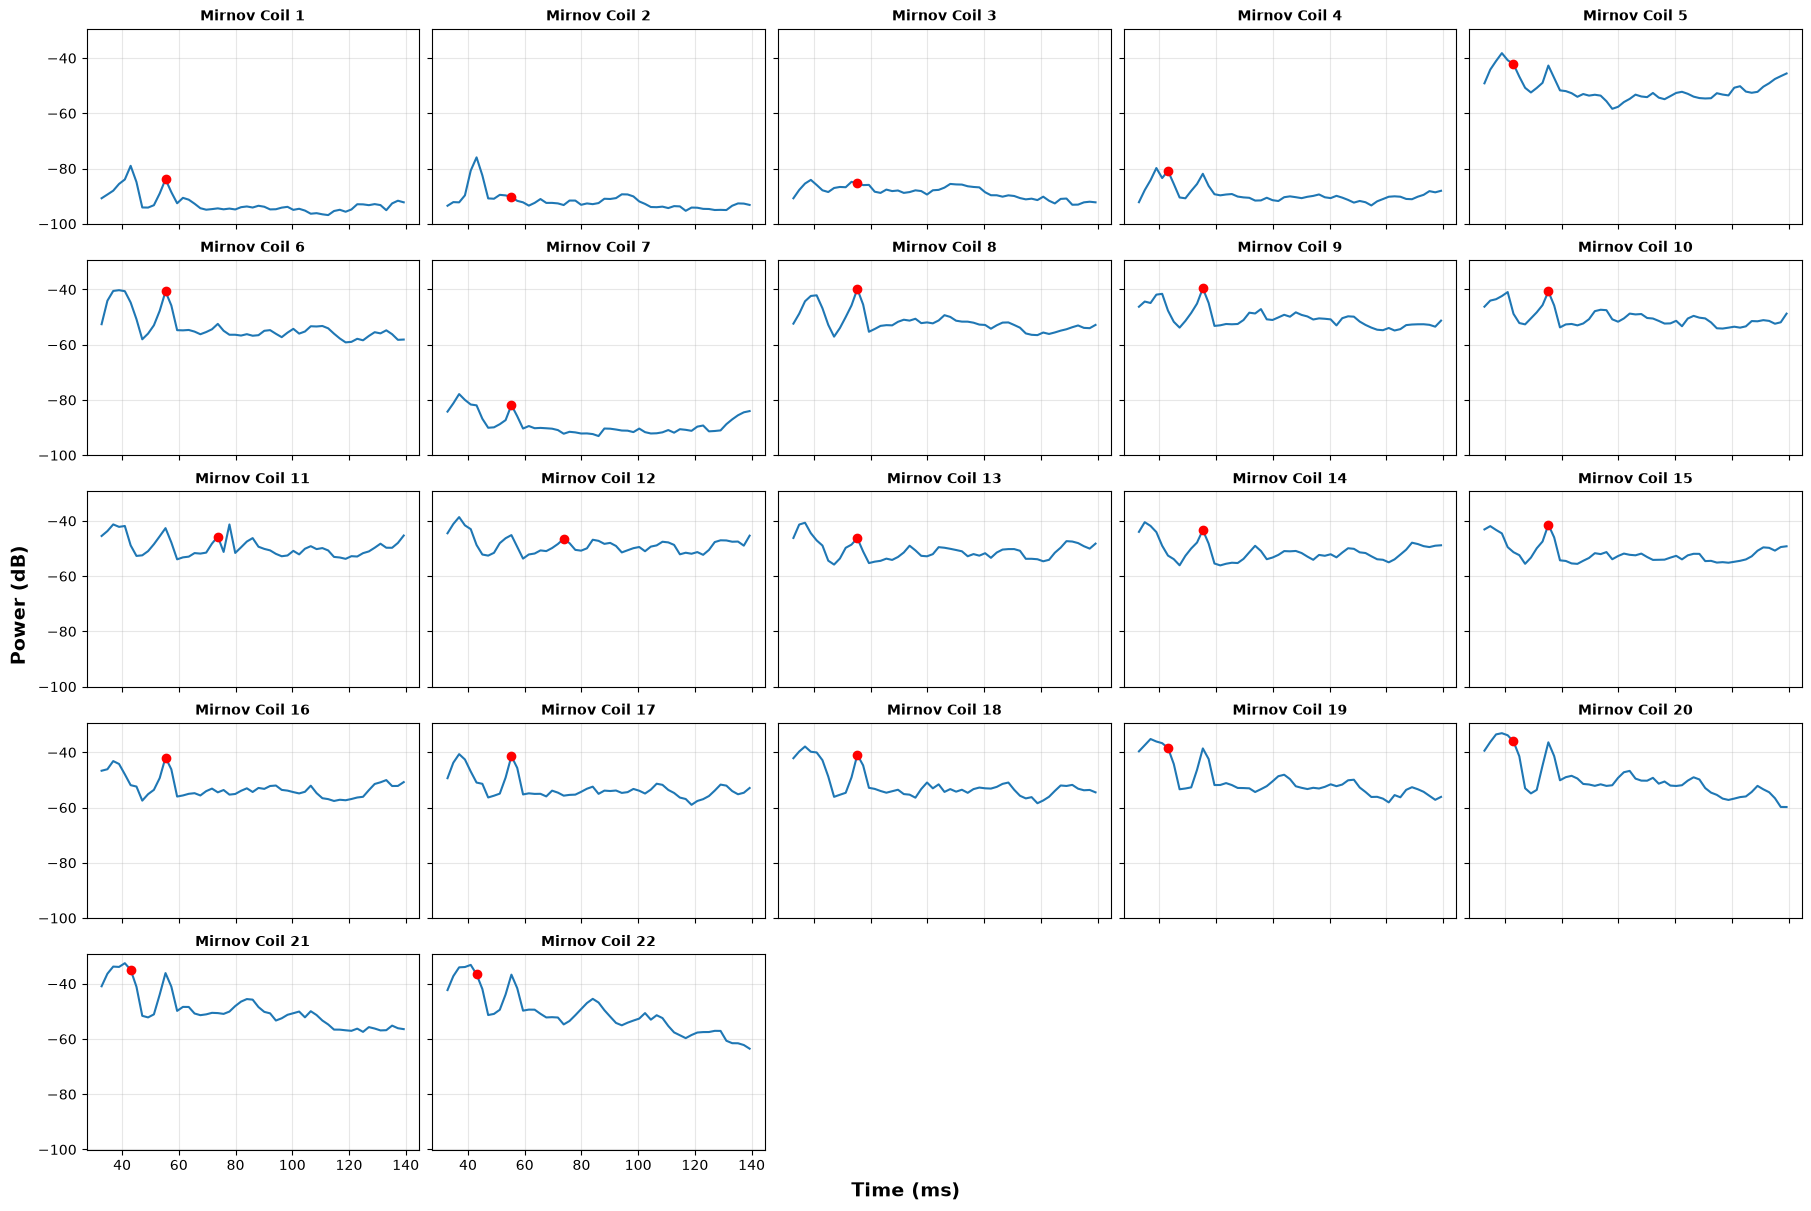

In [105]:
def desenha_ruido(ax, n):
    r = resultados[n]
    ax.plot(r["t_sel"], 10 * np.log10(r["media"] + 1e-20))
    res = r["resumo"]
    if "t_ruido_max" in res:
        ax.plot(res["t_ruido_max"], res["ruido_max"], "ro")
    ax.grid(True, alpha=0.3)


grade(desenha_ruido, resultados, "Power (dB)", sharey=True)
plt.show()

# 9. Table of the data obtained via the all the above analysis 24126

In [106]:
tabela = pd.DataFrame({n: r["resumo"] for n, r in resultados.items()}).T
tabela.round(2)

,t_ini,t_fim,duracao,incerteza,n_trechos,n_atividades,f_min,f_max,f_media,snr_medio,snr_max,t_snr_max,ruido_mediano,ruido_max,t_ruido_max,ruido_desvio
0,38.92,100.38,63.50,2.05,5.0,1.0,12.45,17.09,14.39,20.48,36.50,59.41,-93.98,-83.88,55.31,3.23
1,55.31,73.75,20.48,2.05,2.0,1.0,12.33,15.62,13.26,14.21,20.03,59.41,-92.42,-90.28,55.31,0.94
2,45.07,69.65,26.63,2.05,2.0,1.0,12.45,14.16,12.97,14.80,19.06,63.50,-87.61,-85.29,55.31,1.14
3,43.02,102.42,61.45,2.05,4.0,1.0,12.45,16.96,14.35,20.06,35.57,59.41,-90.37,-80.85,43.02,2.71
4,43.02,83.99,43.02,2.05,4.0,2.0,12.45,16.35,13.63,22.04,34.46,59.41,-53.02,-42.21,43.02,4.27
5,43.02,120.86,79.89,2.05,3.0,1.0,12.45,19.40,15.29,19.30,38.71,59.41,-55.32,-40.72,55.31,3.71
6,43.02,83.99,43.02,2.05,5.0,2.0,12.45,17.70,13.83,21.22,34.53,59.41,-90.29,-81.81,55.31,3.03
7,43.02,122.91,81.94,2.05,5.0,1.0,12.45,19.89,15.21,20.13,38.60,59.41,-52.26,-39.85,55.31,3.23
8,43.02,122.91,81.94,2.05,4.0,1.0,12.45,19.77,15.47,20.00,36.00,59.41,-50.81,-39.56,55.31,2.84
9,43.02,114.72,73.75,2.05,4.0,1.0,12.45,18.55,15.01,21.22,34.45,59.41,-50.74,-40.72,55.31,2.58


# 10. Table of the data 24128

In [93]:
tabela = pd.DataFrame({n: r["resumo"] for n, r in resultados.items()}).T
tabela.round(2)

,t_ini,t_fim,duracao,incerteza,n_trechos,n_atividades,f_min,f_max,f_media,snr_medio,snr_max,t_snr_max,ruido_mediano,ruido_max,t_ruido_max,ruido_desvio
0,75.79,106.52,32.78,2.05,3.0,2.0,9.52,18.43,13.99,19.09,33.95,79.89,-92.75,-90.11,90.13,1.70
1,79.89,86.04,8.19,2.05,2.0,1.0,10.98,11.84,11.55,12.21,14.09,83.99,-91.96,-90.47,79.89,0.73
2,77.84,90.13,14.34,2.05,2.0,2.0,10.86,12.57,11.31,11.78,14.54,79.89,-85.93,-84.71,81.94,1.15
3,75.79,104.47,30.73,2.05,2.0,1.0,10.74,18.31,14.01,19.63,32.40,79.89,-89.50,-87.64,88.09,1.55
4,75.79,90.13,16.39,2.05,2.0,2.0,10.86,14.03,12.04,22.35,34.93,79.89,-52.87,-43.46,43.02,3.44
5,75.79,118.81,45.07,2.05,3.0,2.0,10.74,19.89,15.34,18.26,35.79,79.89,-53.92,-50.00,88.09,2.49
6,75.79,90.13,16.39,2.05,1.0,1.0,10.86,13.79,11.96,22.38,33.57,79.89,-90.04,-88.50,83.99,1.22
7,77.84,116.76,40.97,2.05,2.0,1.0,10.86,19.89,15.87,18.33,36.88,79.89,-52.32,-44.06,88.09,2.78
8,75.79,118.81,45.07,2.05,4.0,1.0,10.74,19.89,15.45,19.54,38.38,79.89,-50.82,-42.73,88.09,3.02
9,75.79,110.62,36.87,2.05,4.0,2.0,10.74,18.92,14.13,22.74,39.42,79.89,-50.17,-43.27,90.13,3.12
